In [12]:
from pathlib import Path
import pandas as pd

HASHTAGS_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\hashtags.json"
)

if not HASHTAGS_PATH.is_file():
    raise FileNotFoundError(f"File non trovato: {HASHTAGS_PATH}")

print(f"Dimensione: {HASHTAGS_PATH.stat().st_size / 1024**2:.1f} MiB")

# Load the JSON file into a DataFrame
df = pd.read_json(HASHTAGS_PATH)

# Export the DataFrame to a CSV file in the same directory
CSV_PATH = HASHTAGS_PATH.with_suffix(".csv")
df.to_csv(CSV_PATH, index=False)

print(f"CSV salvato in: {CSV_PATH}")
print(f"Numero di record: {len(df):,}")
print(f"Versione pandas: {pd.__version__}")

# Display the first 5 rows
df.head()

Dimensione: 19.3 MiB
CSV salvato in: C:\Users\bucco\Desktop\Laboratory of Data Science\project\code_project\data\Project_Data\hashtags.csv
Numero di record: 205,214
Versione pandas: 3.1.0


,id_hashtag,first_seen,hashtag,truth_id,hashtag_id
0,1,2022-09-14 17:29:14.578577,MarkGeist,18,1
1,2,2022-09-14 17:34:04.180279,LIVGolf,21,2
2,2,2022-09-14 17:34:04.180279,LIVGolf,478624,2
3,3,2022-09-14 23:15:11.267669,TrumpTurnberry,37,3
4,3,2022-09-14 23:15:11.267669,TrumpTurnberry,384189,3


In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 205214 entries, 0 to 205213
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   id_hashtag  205214 non-null  int64
 1   first_seen  205214 non-null  str  
 2   hashtag     205214 non-null  str  
 3   truth_id    205214 non-null  int64
 4   hashtag_id  205214 non-null  int64
dtypes: int64(3), str(2)
memory usage: 9.4 MB


In [14]:
df.describe()

,id_hashtag,truth_id,hashtag_id
count,205214.000000,205214.000000,205214.000000
mean,3876.202637,502495.220195,3876.202637
std,5299.927254,245786.422731,5299.927254
min,1.000000,18.000000,1.000000
25%,103.000000,337037.000000,103.000000
50%,1578.000000,509950.000000,1578.000000
75%,5220.000000,715766.000000,5220.000000
max,21599.000000,978140.000000,21599.000000


In [15]:
print(df["id_hashtag"].equals(df["hashtag_id"]))

True


In [16]:
# Step 1: Collect all rows belonging to exact-duplicate groups
all_duplicate_rows = df[df.duplicated(keep=False)].copy()

# Step 2: Display the first 5 rows belonging to duplicate groups
display(all_duplicate_rows)   
# The output should not be the same rows because here 
#I'm printing only the one of the duplicated rows 

# Step 3: Select the first duplicated occurrence
duplicate_rows = df[df.duplicated(keep="first")]

duplicate_index = duplicate_rows.index[0]

# Step 4: Retrieve the values of that row
duplicate_values = df.loc[duplicate_index]

# Step 5: Find rows with exactly the same values
# across all columns, including missing values
matching_rows = df.loc[
    df.eq(duplicate_values).all(axis=1)
    | (df.isna() & duplicate_values.isna()).all(axis=1)
]

# Step 6: Display the matching rows
display(matching_rows)

,id_hashtag,first_seen,hashtag,truth_id,hashtag_id
111426,1751,2022-09-18 04:42:26.983681,PresidentsDay,115737,1751
111427,1751,2022-09-18 04:42:26.983681,PresidentsDay,115737,1751
122523,2494,2022-09-19 01:40:17.722153,ThisDayInHistory,115737,2494
122524,2494,2022-09-19 01:40:17.722153,ThisDayInHistory,115737,2494


,id_hashtag,first_seen,hashtag,truth_id,hashtag_id
111426,1751,2022-09-18 04:42:26.983681,PresidentsDay,115737,1751
111427,1751,2022-09-18 04:42:26.983681,PresidentsDay,115737,1751


In [17]:
# Count duplicate rows, excluding the first occurrence
number_of_duplicates = df.duplicated().sum()

print("Number of duplicate rows:", number_of_duplicates)

Number of duplicate rows: 2


In [18]:
# Returns an array of all distinct IDs
unique_ids = df['id_hashtag'].unique()

print(f"Total unique IDs: {len(unique_ids)}")
print(unique_ids)

Total unique IDs: 21599
[    1     2     3 ... 20272 20273 20274]


In [19]:
df["id_hashtag"].duplicated().equals(
    df["hashtag"].duplicated()
) 

True

In [20]:
df["id_hashtag"].duplicated().equals(
    df["truth_id"].duplicated()
) 

False

In [21]:
df.isnull().sum()

id_hashtag    0
first_seen    0
hashtag       0
truth_id      0
hashtag_id    0
dtype: int64

In [22]:
df['truth_id']

0             18
1             21
2         478624
3             37
4         384189
           ...  
205209    718368
205210    718177
205211    718170
205212    718176
205213    718171
Name: truth_id, Length: 205214, dtype: int64

In [23]:
print("Total rows:", len(df))
print("Unique hashtags:", df["hashtag"].nunique())
print("Unique hashtag IDs:", df["id_hashtag"].nunique())
print("Unique Truth IDs:", df["truth_id"].nunique())

print("\nUnique values per column:")
display(df.nunique())

Total rows: 205214
Unique hashtags: 21599
Unique hashtag IDs: 21599
Unique Truth IDs: 75278

Unique values per column:


id_hashtag    21599
first_seen    21599
hashtag       21599
truth_id      75278
hashtag_id    21599
dtype: int64

In [24]:
# Number of distinct hashtag strings for each ID
names_per_id = df.groupby("id_hashtag")["hashtag"].nunique()

# Number of distinct IDs for each hashtag string
ids_per_name = df.groupby("hashtag")["id_hashtag"].nunique()

print("IDs associated with multiple hashtags:",
      (names_per_id > 1).sum())

print("Hashtags associated with multiple IDs:",
      (ids_per_name > 1).sum())

IDs associated with multiple hashtags: 0
Hashtags associated with multiple IDs: 0


hashtag
Truth                11206
TrumpTruths           6466
DT47                  3801
MAGA                  3199
truth                 2959
Trump                 2278
TruthSocial           1954
FJB                   1926
Covfefe               1920
TRUTH                 1694
dumbTS7500caprule     1461
WWG1WGA               1445
TrumpTrains           1384
2000mules             1292
trumptrains           1272
ReTruth               1248
Trump2024             1118
TrumpWon              1076
Ukraine               1052
MAGAA                 1043
Name: count, dtype: int64

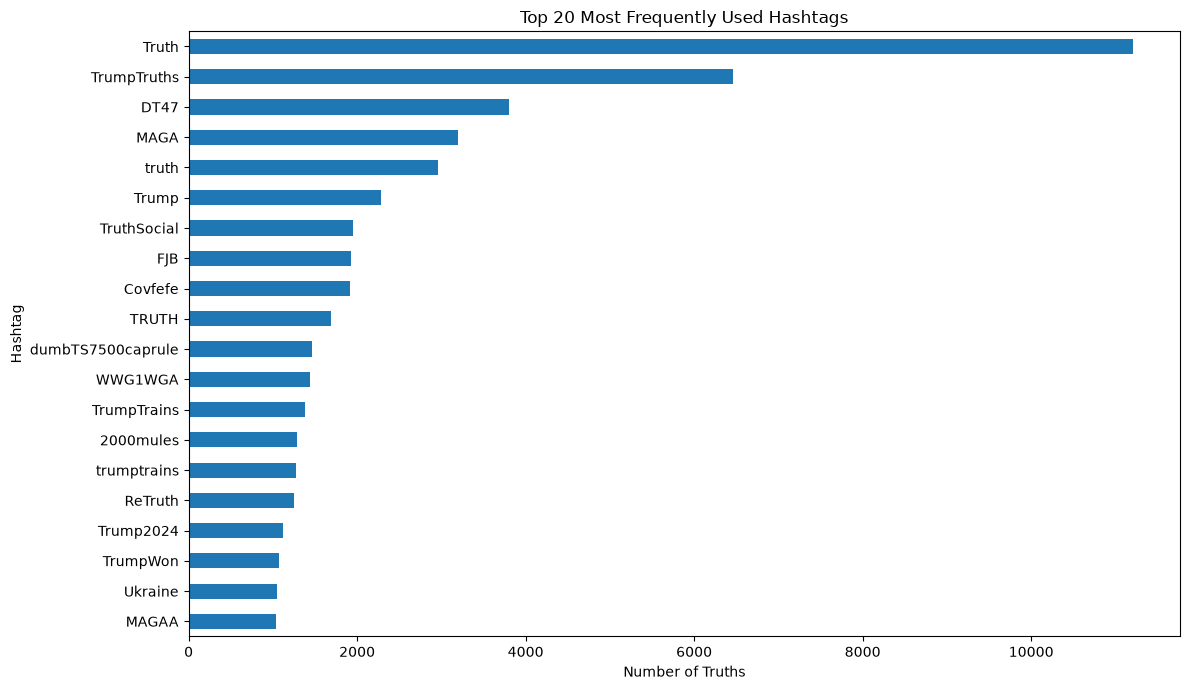

In [25]:
import matplotlib.pyplot as plt

top_hashtags = (
    df.drop_duplicates(subset=["truth_id", "id_hashtag"])
      ["hashtag"]
      .value_counts()
      .head(20)
)

display(top_hashtags)

plt.figure(figsize=(12, 7))
top_hashtags.sort_values().plot(kind="barh")

plt.title("Top 20 Most Frequently Used Hashtags")
plt.xlabel("Number of Truths")
plt.ylabel("Hashtag")
plt.tight_layout()
plt.show()

count    75278.000000
mean         2.726055
std          3.652068
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max         56.000000
Name: id_hashtag, dtype: float64

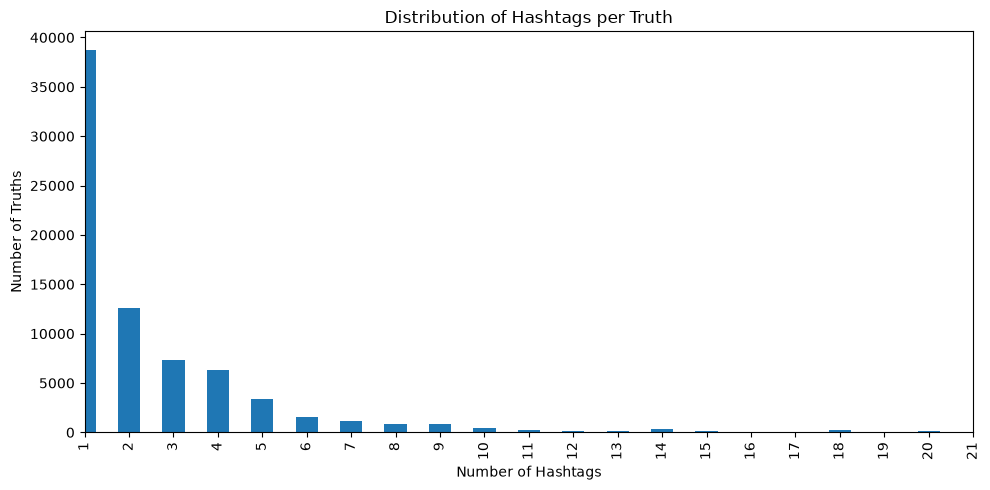

In [26]:
hashtags_per_truth = (
    df.groupby("truth_id")["id_hashtag"].nunique()
)

display(hashtags_per_truth.describe())

plt.figure(figsize=(10, 5))
hashtags_per_truth.value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution of Hashtags per Truth")
plt.xlabel("Number of Hashtags")
plt.ylabel("Number of Truths")
plt.xlim(0, 20)
plt.tight_layout()
plt.show()

In [27]:
df["first_seen"] = pd.to_datetime(
    df["first_seen"],
    errors="coerce"
)

print("Earliest first_seen:", df["first_seen"].min())
print("Latest first_seen:", df["first_seen"].max())
print("Invalid dates:", df["first_seen"].isna().sum())

Earliest first_seen: 2022-09-14 17:29:14.578577
Latest first_seen: 2022-11-10 19:09:27.834105
Invalid dates: 0


In [28]:
first_seen_per_hashtag = (
    df.groupby("id_hashtag")["first_seen"].nunique()
)

print("Hashtags with multiple first_seen values:",
      (first_seen_per_hashtag > 1).sum())

Hashtags with multiple first_seen values: 0


In [30]:
from pathlib import Path
import pandas as pd

# Define the path to the truths dataset
TRUTHS_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\truths.csv"
)

# Check if the file exists
if not TRUTHS_PATH.is_file():
    raise FileNotFoundError(f"File not found: {TRUTHS_PATH}")

# Load only the ID column to reduce memory usage
truths_df = pd.read_csv(
    TRUTHS_PATH,
    usecols=["id"]
)

# Ensure consistent data types for comparison
hashtag_truth_ids = set(
    pd.to_numeric(df["truth_id"], errors="coerce").dropna()
)

truth_ids = set(
    pd.to_numeric(truths_df["id"], errors="coerce").dropna()
)

# Check referential integrity
matched_ids = hashtag_truth_ids & truth_ids
unmatched_ids = hashtag_truth_ids - truth_ids

# Calculate match rate
match_rate = (
    len(matched_ids) / len(hashtag_truth_ids) * 100
    if hashtag_truth_ids else 0
)

print("REFERENTIAL INTEGRITY CHECK")
print("---------------------------")
print(f"Unique Truth IDs in hashtags.json: {len(hashtag_truth_ids):,}")
print(f"Unique Truth IDs in truths.csv: {len(truth_ids):,}")
print(f"Matched Truth IDs: {len(matched_ids):,}")
print(f"Unmatched Truth IDs: {len(unmatched_ids):,}")
print(f"Match rate: {match_rate:.2f}%")

REFERENTIAL INTEGRITY CHECK
---------------------------
Unique Truth IDs in hashtags.json: 75,278
Unique Truth IDs in truths.csv: 1,038,821
Matched Truth IDs: 64,100
Unmatched Truth IDs: 11,178
Match rate: 85.15%


In [31]:
# Identify hashtag records associated with unmatched Truth IDs
unmatched_records = df[
    pd.to_numeric(df["truth_id"], errors="coerce").isin(unmatched_ids)
]

# Calculate the percentage of affected records
unmatched_percentage = (
    len(unmatched_records) / len(df) * 100
)

print("UNMATCHED HASHTAG RECORDS")
print("-------------------------")
print(f"Total hashtag records: {len(df):,}")
print(f"Unmatched hashtag records: {len(unmatched_records):,}")
print(f"Percentage of affected records: {unmatched_percentage:.2f}%")

# Display a sample
display(unmatched_records.head(10))

UNMATCHED HASHTAG RECORDS
-------------------------
Total hashtag records: 205,214
Unmatched hashtag records: 36,627
Percentage of affected records: 17.85%


,id_hashtag,first_seen,hashtag,truth_id,hashtag_id
19,5,2022-09-14 23:15:39.463634,Alaska,562384,5
31,5,2022-09-14 23:15:39.463634,Alaska,892604,5
33,5,2022-09-14 23:15:39.463634,Alaska,970375,5
61,7,2022-09-15 01:56:29.460178,CrookedHillary,903228,7
62,7,2022-09-15 01:56:29.460178,CrookedHillary,958197,7
77,8,2022-09-15 01:56:52.242970,SundayFunday,875879,8
78,8,2022-09-15 01:56:52.242970,SundayFunday,925819,8
79,8,2022-09-15 01:56:52.242970,SundayFunday,976192,8
87,10,2022-09-15 01:57:02.234735,HillaryClinton,106536,10
88,10,2022-09-15 01:57:02.234735,HillaryClinton,114739,10
